In [73]:
import pandas as pd

hits = pd.read_csv('pep_hits_wo_taxa_to_remove_091826.csv')

peps_metadata = pd.read_csv('lassa_library_sequences_species_standardized_070726_ICTV_corrected.csv')

In [7]:
lasv_hits = hits.loc[hits['species'] == 'Mammarenavirus lassaense'].sort_values(by='sensitivity', ascending=False)

In [ ]:
## all RPK data

df_all_rpk_avg = pd.read_csv("./preprocessing/rpk_df_technical_replicates_samples_passing_readcounts_100k_all_averaged_071626.csv")
df_all_rpk_avg = df_all_rpk_avg.set_index('peptide')
df_avg = df_all_rpk_avg

In [14]:
metadata = pd.read_csv("./preprocessing/master_sample_metadata_060626.csv")

### z score over us healthies

In [62]:
import numpy as np

hbdb_df = pd.read_csv("./preprocessing/hbdb_pass_100k_techreps_averaged_071626.csv").set_index("peptide")

df_avg = df_avg[df_avg.max(axis=1) > 5]

cohort_df = df_avg.filter(regex='(^S-|^C-)')

mat = cohort_df.apply(pd.to_numeric, errors="coerce").fillna(0.0) #converts every column to a numeric type, if cannot be converted, fills with Nan, but then later NaN gets converted to 0.0

#log transforming before z-scoring
log_mat = np.log10(mat + 1.0)

log_hbdb = np.log10(hbdb_df + 1.0)

In [63]:
log_hbdb_mean = log_hbdb.mean(axis=1)

log_hbdb_std = log_hbdb.std(axis=1, ddof=1)
#to prevent inflated z-scores set threshold above a small percentile of the nonzero std
#quantile 0.01 picks a value where roughly the bottom 1% of peptides sit at or below it. so it's
#grounded by a small group of low-variance peptides rather than a single outlier. 
floor = log_hbdb_std[log_hbdb_std > 0].quantile(0.01)
log_hbdb_std = log_hbdb_std.clip(lower=floor)

#z-score using healthy controls as reference
z_mat = log_mat.sub(log_hbdb_mean, axis=0).div(log_hbdb_std, axis=0) #this aligns by peptide index
z_mat = z_mat.fillna(0.0)

z_mat.to_csv('z_score_df_SL_all_tp_over_US_101826.csv')

### keep participants with >= 2 time points

In [64]:
n_tp = metadata.groupby('participant_id')['sample_id'].nunique()

longitudinal = n_tp[n_tp >= 2].index

meta_long = metadata[metadata['participant_id'].isin(longitudinal)]

In [65]:
meta_long.head(2)

,sample_id,participant_id,collection_date,collection_year,collection_month,collection_year_month,baseline_date,days_since_baseline,years_since_baseline,visit_number,...,lassa_ID,lassa_Enrolled_Type,lassa_District,lassa_Chiefdom,lassa_VillageTown,missing_sex,missing_age_years,missing_district,missing_chiefdom,missing_village
3,C-110-1_2_A5,C-110-1,12/10/18,2018,12,2018-12,12/10/18,0,0.00,1,...,110-1,Contact to 110,Kenema,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,C-110-1_6_A4,C-110-1,3/11/22,2022,3,2022-03,12/10/18,1187,3.25,2,...,110-1,Contact to 110,Kenema,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [69]:
z_mat_lasv_hits = z_mat.loc[lasv_hits.peptide]

In [79]:
long_lasv_hits = z_mat_lasv_hits.reset_index().melt(id_vars='peptide', var_name='sample_id', value_name='z_score').merge(meta_long, on='sample_id', how='inner')

In [80]:
long_lasv_hits.head()

,peptide,sample_id,z_score,participant_id,collection_date,collection_year,collection_month,collection_year_month,baseline_date,days_since_baseline,...,lassa_ID,lassa_Enrolled_Type,lassa_District,lassa_Chiefdom,lassa_VillageTown,missing_sex,missing_age_years,missing_district,missing_chiefdom,missing_village
0,AZI96407.1|nucleoprotein|Mammarenavirus_lassae...,C-452-2_5_H3,2.907105,C-452-2,3/11/22,2022,3,2022-03,9/23/19,900,...,452-2,Contact to 452,Kenema,NaN,NaN,NaN,yes,NaN,yes,yes
1,WKK95338.1|nucleoprotein|Mammarenavirus_lassae...,C-452-2_5_H3,1.228131,C-452-2,3/11/22,2022,3,2022-03,9/23/19,900,...,452-2,Contact to 452,Kenema,NaN,NaN,NaN,yes,NaN,yes,yes
2,WNI01985.1|nucleoprotein|Mammarenavirus_lassae...,C-452-2_5_H3,1.338051,C-452-2,3/11/22,2022,3,2022-03,9/23/19,900,...,452-2,Contact to 452,Kenema,NaN,NaN,NaN,yes,NaN,yes,yes
3,AZI96445.1|nucleoprotein|Mammarenavirus_lassae...,C-452-2_5_H3,3.130981,C-452-2,3/11/22,2022,3,2022-03,9/23/19,900,...,452-2,Contact to 452,Kenema,NaN,NaN,NaN,yes,NaN,yes,yes
4,AZI95980.1|nucleoprotein|Mammarenavirus_lassae...,C-452-2_5_H3,-0.259597,C-452-2,3/11/22,2022,3,2022-03,9/23/19,900,...,452-2,Contact to 452,Kenema,NaN,NaN,NaN,yes,NaN,yes,yes


In [81]:
peps_metadata['peptide'] = peps_metadata['seq_id']

long_lasv_hits = long_lasv_hits.merge(peps_metadata[['peptide', 'sequence', 'protein_name', 'protein_std']], on='peptide', how='inner')

In [84]:
long_lasv_hits['reactive'] = long_lasv_hits['z_score'] > 3

In [ ]:
is_base = long_lasv_hits['days_since_baseline'] == long_lasv_hits.groupby('participant_id')['days_since_baseline'].transform('min')

baseline = long_lasv_hits[is_base]

#each participant's baeline reactive peptide set from the filtered sens spec peptide hits
base_set = baseline.loc[baseline['reactive'], ['participant_id', 'peptide']]

#trk is filtered on the baseline reactive ppetides for each individual
trk = long_lasv_hits.merge(base_set, on=['participant_id', 'peptide']) #inner merge preseves only participant peptide pairs present in base_set, across all tps

In [105]:
long_lasv_hits_np = long_lasv_hits.loc[long_lasv_hits['protein_std'] == 'nucleoprotein']
trk_np = trk[trk['protein_std'] == 'nucleoprotein']

In [107]:
n_base_np = trk_np.groupby('participant_id')['peptide'].nunique().rename('n_baseline')

count    100.0
mean     100.0
std        0.0
min      100.0
25%      100.0
50%      100.0
75%      100.0
max      100.0
Name: pct_retained, dtype: float64


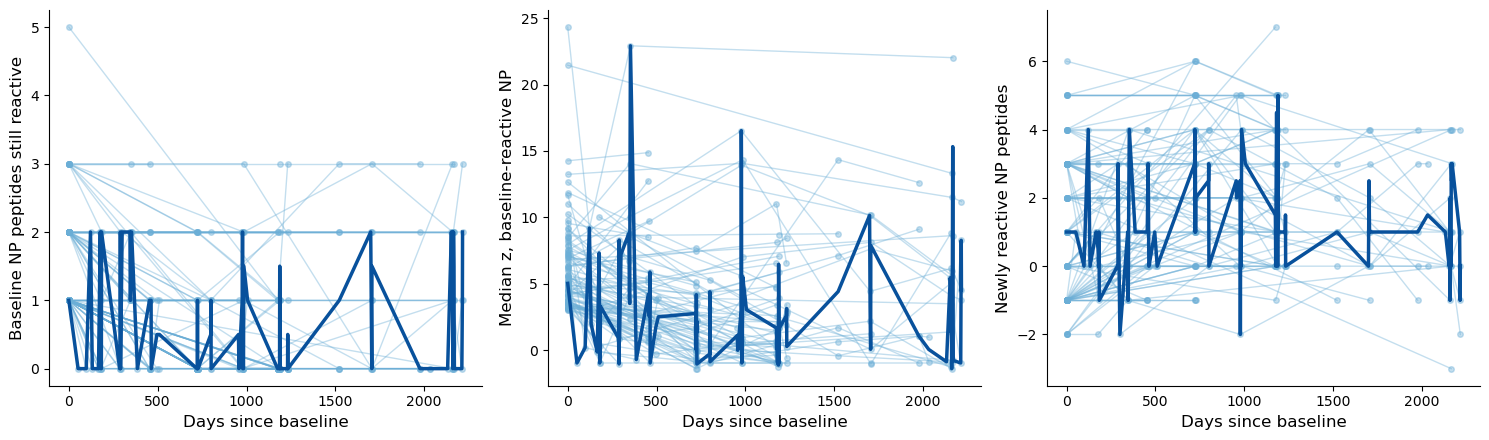

n_retained   slope/day = -0.00041  p = 1.43e-13
median_z     slope/day = -0.00150  p = 3.9e-08
n_gained     slope/day = +0.00021  p = 0.113
                                                    frac_still_reactive  \
peptide                                                                   
AZI96488.1|precursor|Mammarenavirus_lassaense|L...             0.676471   
AZI96476.1|precursor|Mammarenavirus_lassaense|L...             0.583333   
AZI96059.1|precursor|Mammarenavirus_lassaense|L...             0.340000   
AZI96476.1|precursor|Mammarenavirus_lassaense|L...             0.250000   
ANH09740.1|precursor|Mammarenavirus_lassaense|?...             0.162791   

                                                    n_participants  
peptide                                                             
AZI96488.1|precursor|Mammarenavirus_lassaense|L...              48  
AZI96476.1|precursor|Mammarenavirus_lassaense|L...              47  
AZI96059.1|precursor|Mammarenavirus_lassaense|L...        

In [119]:
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

trk_np     = trk[trk['protein_std'] == 'glycoprotein']
n_base_np  = trk_np.groupby('participant_id')['peptide'].nunique().rename('n_baseline')

# --- 1. breadth: retained / total / gained ---
retained = (trk_np.groupby(['participant_id', 'days_since_baseline'])['reactive']
                  .sum().reset_index(name='n_retained'))

total = (long_lasv_hits_np.groupby(['participant_id', 'days_since_baseline'])['reactive']
                          .sum().reset_index(name='n_total'))

b = (retained.merge(total, on=['participant_id', 'days_since_baseline'])
             .merge(n_base_np, on='participant_id'))
b['pct_retained'] = 100 * b['n_retained'] / b['n_baseline']
b['n_gained']     = b['n_total'] - b['n_retained']

# --- 2. magnitude ---
mag = (trk_np.groupby(['participant_id', 'days_since_baseline'])['z_score']
             .median().reset_index(name='median_z'))
b = b.merge(mag, on=['participant_id', 'days_since_baseline'])

# sanity: 100% at each participant's first timepoint
print(b.loc[b.groupby('participant_id')['days_since_baseline'].idxmin(), 'pct_retained'].describe())

# --- 3. plot ---
panels = [('n_retained', 'Baseline NP peptides still reactive'),
          ('median_z',   'Median z, baseline-reactive NP'),
          ('n_gained',   'Newly reactive NP peptides')]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (col, lab) in zip(axes, panels):
    for pid, g in b.sort_values('days_since_baseline').groupby('participant_id'):
        ax.plot(g['days_since_baseline'], g[col], marker='o', ms=4,
                lw=1, alpha=0.4, color='#6baed6')
    m = b.groupby('days_since_baseline')[col].median()
    ax.plot(m.index, m.values, lw=2.5, color='#08519c')
    ax.set_xlabel('Days since baseline', fontsize=12)
    ax.set_ylabel(lab, fontsize=12)
    ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.savefig('np_longitudinal.svg', format='svg')
plt.show()

# --- 4. test trends ---
for col in ['n_retained', 'median_z', 'n_gained']:
    m = smf.mixedlm(f"{col} ~ days_since_baseline", b, groups=b['participant_id']).fit()
    print(f"{col:12} slope/day = {m.params['days_since_baseline']:+.5f}  p = {m.pvalues['days_since_baseline']:.3g}")

# --- 5. which NP epitopes persist ---
late = trk_np[trk_np['days_since_baseline'] > 180]
durability = (late.groupby('peptide')
                  .agg(frac_still_reactive=('reactive', 'mean'),
                       n_participants=('participant_id', 'nunique'))
                  .query('n_participants >= 3')
                  .sort_values('frac_still_reactive', ascending=False))
print(durability.head(20))

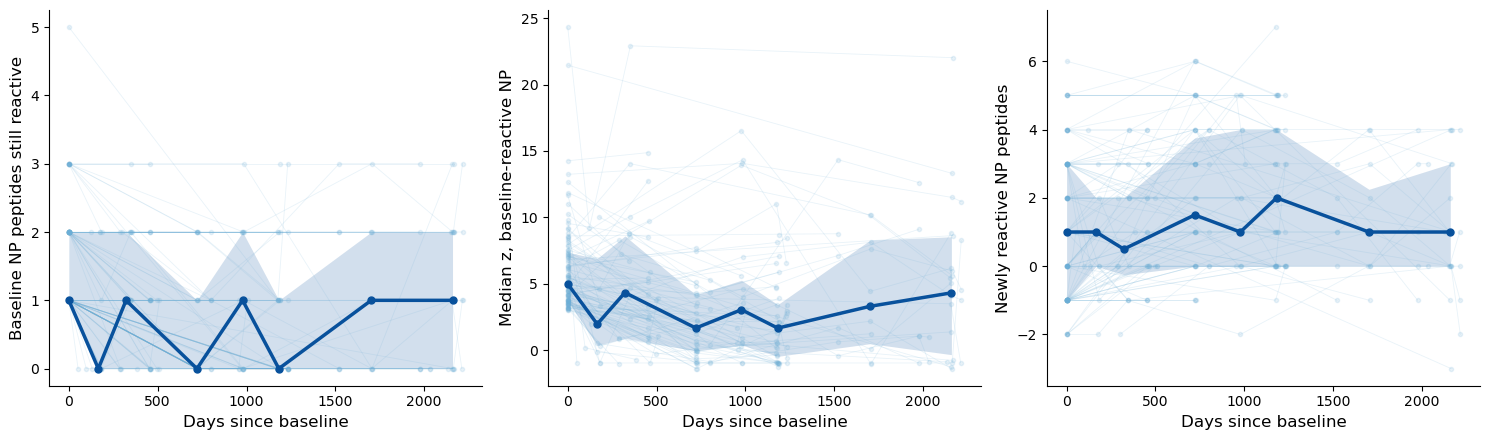

tbin
0-3m     96
3-6m      7
6-12m    20
1-2y     54
2-3y     25
3-4y     45
4-5y     16
5y+      30
dtype: int64


In [120]:
import numpy as np

bins   = [0, 90, 180, 365, 730, 1095, 1460, 1825, np.inf]
labels = ['0-3m', '3-6m', '6-12m', '1-2y', '2-3y', '3-4y', '4-5y', '5y+']
b['tbin'] = pd.cut(b['days_since_baseline'], bins=bins, labels=labels, right=False)
b['tmid'] = b.groupby('tbin', observed=True)['days_since_baseline'].transform('median')

panels = [('n_retained', 'Baseline NP peptides still reactive'),
          ('median_z',   'Median z, baseline-reactive NP'),
          ('n_gained',   'Newly reactive NP peptides')]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (col, lab) in zip(axes, panels):
    for pid, g in b.sort_values('days_since_baseline').groupby('participant_id'):
        ax.plot(g['days_since_baseline'], g[col], marker='o', ms=3,
                lw=0.6, alpha=0.15, color='#6baed6')

    agg = (b.groupby('tbin', observed=True)
             .agg(x=('tmid','first'), med=(col,'median'),
                  lo=(col, lambda s: s.quantile(.25)),
                  hi=(col, lambda s: s.quantile(.75)),
                  n=(col,'size')).dropna())
    ax.fill_between(agg['x'], agg['lo'], agg['hi'], color='#08519c', alpha=0.18, lw=0)
    ax.plot(agg['x'], agg['med'], lw=2.5, color='#08519c', marker='o', ms=5)

    ax.set_xlabel('Days since baseline', fontsize=12)
    ax.set_ylabel(lab, fontsize=12)
    ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

print(b.groupby('tbin', observed=True).size())   # n per bin — check the tail

/tmp/ipykernel_1740515/337575727.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f'{l}\n(n={counts.get(l,0)})' for l in counts.index], fontsize=11)


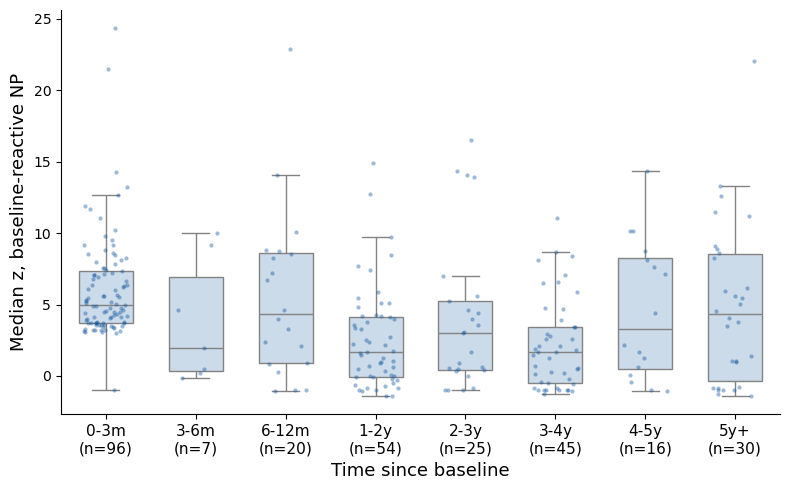

In [121]:
import seaborn as sns

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=b, x='tbin', y='median_z', ax=ax, color='#c6dbef',
            fliersize=0, width=0.6)
sns.stripplot(data=b, x='tbin', y='median_z', ax=ax, color='#08519c',
              size=3, alpha=0.4, jitter=0.25)
ax.set_xlabel('Time since baseline', fontsize=13)
ax.set_ylabel('Median z, baseline-reactive NP', fontsize=13)
ax.spines[['top','right']].set_visible(False)

# n per bin under each box
counts = b.groupby('tbin', observed=True).size()
ax.set_xticklabels([f'{l}\n(n={counts.get(l,0)})' for l in counts.index], fontsize=11)
plt.tight_layout()

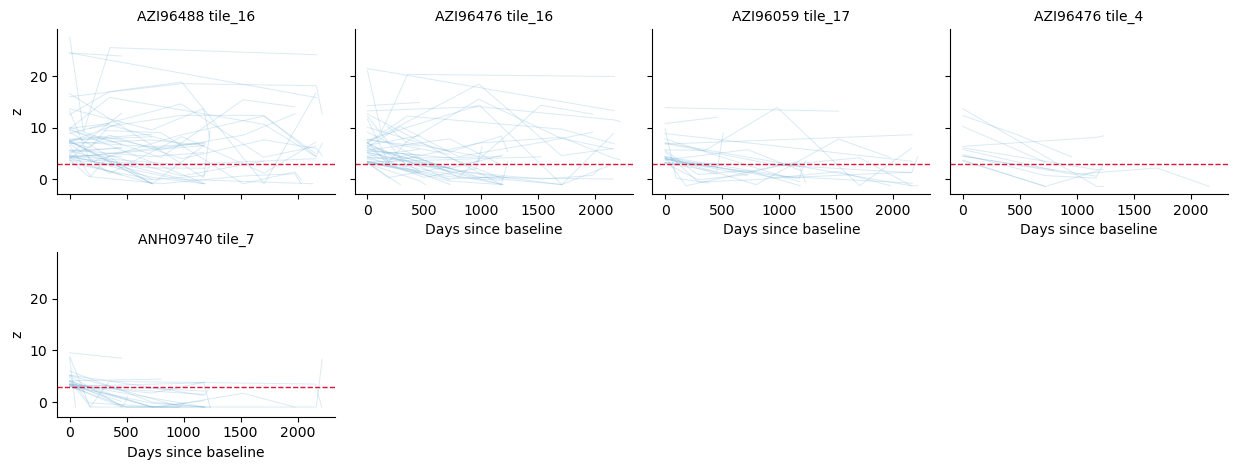

In [122]:
import seaborn as sns

def short(p):
    parts = p.split('|')
    return f"{parts[0].split('.')[0]} {parts[-1]}"   # e.g. 'ANH09741 tile_16'

trk_np = trk_np.copy()
trk_np['pep_short'] = trk_np['peptide'].map(short)

peps = trk_np['pep_short'].value_counts().head(12).index
g = sns.relplot(
    data=trk_np[trk_np.pep_short.isin(peps)],
    x='days_since_baseline', y='z_score', col='pep_short', col_wrap=4,
    kind='line', units='participant_id', estimator=None,
    color='#6baed6', alpha=0.25, lw=0.7,
    height=2.4, aspect=1.3, facet_kws={'sharey': True})
for ax in g.axes.flat:
    ax.axhline(3, ls='--', lw=1, color='crimson')
g.set_titles('{col_name}', size=10)
g.set_axis_labels('Days since baseline', 'z')
plt.tight_layout()

In [118]:
trk_np['tile'] = trk_np['peptide'].str.extract(r'tile_(\d+)$').astype(int)
trk_np['strain'] = trk_np['peptide'].str.split('|').str[0].str.split('.').str[0]

# how much redundancy is there?
print(trk_np.groupby('tile')['strain'].nunique())

collapsed = (trk_np.groupby(['participant_id','days_since_baseline','tile'])
                   .agg(z=('z','max')).reset_index())
collapsed['reactive'] = collapsed['z'] > 3

tile
6     1
7     1
16    5
Name: strain, dtype: int64


KeyError: "Column(s) ['z'] do not exist"

In [100]:
breadth = (long_lasv_hits_np.groupby(['participant_id', 'days_since_baseline']).agg(n_reactive=('reactive', 'sum'), 
        n_peps_looked_at=('peptide', 'size')).reset_index())

breadth['pct_retained'] = 100 * breadth['n_reactive'] / breadth['n_peps_looked_at']

In [101]:
breadth.head(30)

,participant_id,days_since_baseline,n_reactive,n_peps_looked_at,pct_retained
0,C-110-1,0,0,7,0.000000
1,C-110-1,1187,1,7,14.285714
2,C-110-2,0,2,7,28.571429
3,C-110-2,1188,1,7,14.285714
4,C-110-3,0,3,7,42.857143
5,C-110-3,1190,3,7,42.857143
6,C-110-3,1235,1,7,14.285714
7,C-111-1,0,4,7,57.142857
8,C-111-1,722,5,7,71.428571
9,C-111-1,1176,4,7,57.142857
